# STAR Project – The Grade 5 Drop

In `01_explore_data.ipynb` we saw that far fewer students have a test score in **grade 5** than in grade 4 or grade 6.
This notebook checks **why** this happens and **whether it is a problem** for our research question:

> Does the benefit of small classes (K–3) last over time, up to grade 8 and high school?

**What the user guide says** (`data/raw/starUsersGuide.pdf`, section 2.6):

> "We have no clear explanation for the smaller number of achievement test scores in grade 5.
> The attempt to match STAR files with those of the Tennessee State Department of Education
> did not yield as many cases at the time."

So the official explanation is a **record-matching problem**, not students leaving the study. We check this with the data.

**Plan**
1. Describe the drop
2. Attrition or missing records? (follow students through grades 4 → 5 → 6)
3. Where did it happen? (schools)
4. Who is missing? (compare students, logistic regression)
5. Is missingness related to class type? (the key question for us)
6. Does it change the results? (small-class effect in grade 5, three ways)
7. Conclusion and decision for the main analysis

## 0. Setup and load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 50)

df = pd.read_spss("../data/raw/STAR_Students.sav")
print(df.shape)

grades = ["gk", "g1", "g2", "g3", "g4", "g5", "g6", "g7", "g8"]
labels = ["K", "1", "2", "3", "4", "5", "6", "7", "8"]
k3 = ["gk", "g1", "g2", "g3"]

GREY, RED, BLUE = "#B8BEC6", "#D1495B", "#4C78A8"

(11601, 379)


### Helper variables

All built from the **K–3 years**, when the experiment ran:

- `first_classtype` – the class type in the first grade the student appears in K–3 (same as in notebook 01).
- `small` – 1 if the first class type is **small**, 0 if regular or regular + aide.
- `first_school` – the school in that first grade. Randomization was done **within schools**, so we use it as a control.
- `freelunch`, `urban` – first available value in K–3.
- `race3` – White / Black / Other (the other groups are very small).
- `in_g4`, `in_g5`, `in_g6` – the student has achievement data in that grade (`flagg4`, `flagg5`, `flagg6`).
- `has_g5_math` – the student has a grade 5 total math score.

In [2]:
def first_in_k3(var):
    """First non-missing value of g?{var} across K-3, as text."""
    cols = [f"{g}{var}" for g in k3]
    return df[cols].astype(object).bfill(axis=1).iloc[:, 0]

new = pd.DataFrame(index=df.index)
new["first_classtype"] = first_in_k3("classtype")
new["first_school"] = first_in_k3("schid")
new["freelunch"] = first_in_k3("freelunch")
new["urban"] = first_in_k3("surban")
new["small"] = (new["first_classtype"] == "SMALL CLASS").astype(int)
new["race3"] = df["race"].astype(object).map({"WHITE": "White", "BLACK": "Black"}).fillna("Other")
new.loc[df["race"].isna(), "race3"] = np.nan
for g in ["g4", "g5", "g6", "g7", "g8"]:
    new[f"in_{g}"] = (df[f"flag{g}"] == "YES").astype(int)
new["has_g5_math"] = df["g5tmathss"].notna().astype(int)

df = pd.concat([df, new], axis=1).copy()   # one concat = no fragmentation warning
df[["first_classtype", "small", "first_school", "freelunch", "urban", "race3", "in_g4", "in_g5", "in_g6"]].head()

,first_classtype,small,first_school,freelunch,urban,race3,in_g4,in_g5,in_g6
0,REGULAR + AIDE CLASS,0,170295.0,FREE LUNCH,RURAL,White,1,1,0
1,REGULAR + AIDE CLASS,0,169229.0,NON-FREE LUNCH,SUBURBAN,White,0,0,1
2,REGULAR + AIDE CLASS,0,205492.0,NaN,SUBURBAN,Black,1,0,1
3,REGULAR CLASS,0,257899.0,NON-FREE LUNCH,RURAL,White,1,0,1
4,REGULAR + AIDE CLASS,0,244796.0,FREE LUNCH,INNER CITY,Black,1,0,1


## 1. Describe the drop

How many students have a score in each grade? We look at **math**, **reading** and the general
"achievement data available" flag. If all three drop in grade 5, the problem is the whole grade 5 record, not one test.

In [3]:
counts = pd.DataFrame({
    "math (tmathss)":   [df[f"{g}tmathss"].notna().sum() for g in grades],
    "reading (treadss)": [df[f"{g}treadss"].notna().sum() for g in grades],
}, index=labels)
counts.loc[["4", "5", "6", "7", "8"], "data flag (flagg?)"] = [df[f"in_g{l}"].sum() for l in ["4", "5", "6", "7", "8"]]
counts["schools"] = [df[f"{g}schid"].nunique() for g in grades]
counts

,math (tmathss),reading (treadss),data flag (flagg?),schools
K,5871,5789,NaN,79
1,6598,6395,NaN,76
2,6065,6077,NaN,75
3,6077,6000,NaN,75
4,4331,6005,6339.0,76
5,2589,2591,2593.0,56
6,6422,6428,6441.0,525
7,4888,4906,4942.0,181
8,6213,6224,6361.0,406


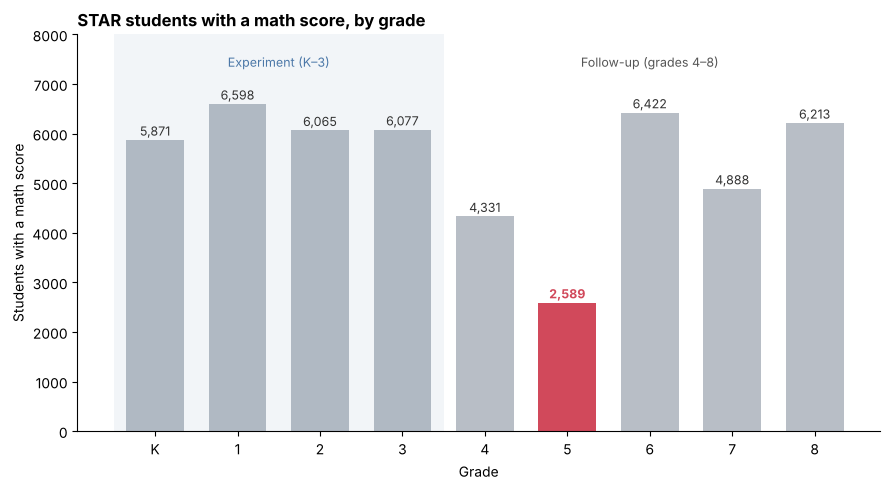

Grade 5 has 40% fewer math scores than grade 4.


In [4]:
n_math = counts["math (tmathss)"]
colors = [RED if l == "5" else GREY for l in labels]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, n_math, color=colors, width=0.7)
for b, v, l in zip(bars, n_math, labels):
    ax.text(b.get_x() + b.get_width() / 2, v + 90, f"{v:,}", ha="center", fontsize=9,
            color=RED if l == "5" else "#333", fontweight="bold" if l == "5" else "normal")
ax.axvspan(-0.5, 3.5, color=BLUE, alpha=0.07, lw=0)
ax.text(1.5, 7350, "Experiment (K–3)", ha="center", fontsize=9, color=BLUE)
ax.text(6, 7350, "Follow-up (grades 4–8)", ha="center", fontsize=9, color="#555")
ax.set_ylim(0, 8000)
ax.set_xlabel("Grade")
ax.set_ylabel("Students with a math score")
ax.set_title("STAR students with a math score, by grade", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../figures/grade5_students_by_grade.png", dpi=200)
plt.show()

drop = 1 - n_math["5"] / n_math["4"]
print(f"Grade 5 has {drop:.0%} fewer math scores than grade 4.")

**What we see:** math, reading and the data flag all drop together in grade 5 (about 2,600 students, 40% fewer than
grade 4 math), and the number of schools also drops, from 76 in grade 4 to 56 in grade 5.
Grade 6 is back up, with many more schools, because grade 6 is in middle schools and K–6 schools all over the state.

Side note: in grade 4, **reading** has about 6,000 scores but **math** only about 4,300. That is a separate gap, worth checking later.

## 2. Attrition or missing records?

If students really **left** the study in grade 5, they should also be missing in grade 6.
If it is a **record-matching problem**, many of them should come back in grade 6.

We take all students with grade 4 data and look at their pattern in grades 4 → 5 → 6.

In [5]:
g4 = df[df["in_g4"] == 1].copy()

def pattern(row):
    return ("4 " + ("5 " if row["in_g5"] else "– ") + ("6" if row["in_g6"] else "–"))

g4["pattern"] = g4.apply(pattern, axis=1)
pat = g4["pattern"].value_counts().rename("students").to_frame()
pat["percent"] = (pat["students"] / len(g4) * 100).round(1)
pat.index.name = "grades with data"
pat

,students,percent
grades with data,,
4 – 6,2454,38.7
4 5 6,2292,36.2
4 – –,1292,20.4
4 5 –,301,4.7


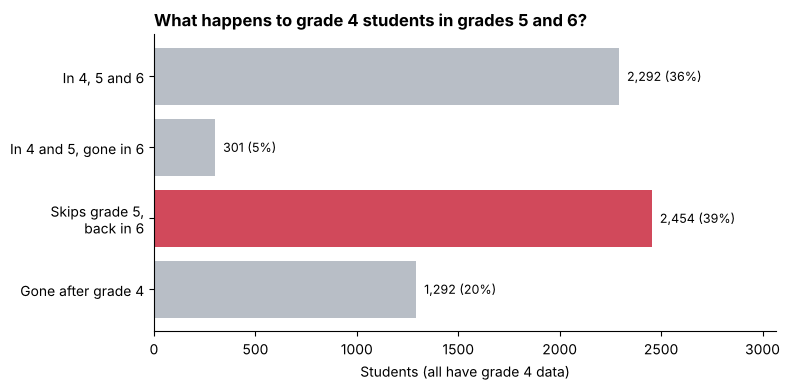

In [6]:
order = ["4 5 6", "4 5 –", "4 – 6", "4 – –"]
names = {"4 5 6": "In 4, 5 and 6",
         "4 5 –": "In 4 and 5, gone in 6",
         "4 – 6": "Skips grade 5,\nback in 6",
         "4 – –": "Gone after grade 4"}
vals = pat.reindex(order)["students"].fillna(0)

fig, ax = plt.subplots(figsize=(8, 4))
c = [GREY, GREY, RED, GREY]
ax.barh([names[o] for o in order], vals, color=c)
for i, v in enumerate(vals):
    ax.text(v + 40, i, f"{int(v):,} ({v / len(g4):.0%})", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Students (all have grade 4 data)")
ax.set_title("What happens to grade 4 students in grades 5 and 6?", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, vals.max() * 1.25)
plt.tight_layout()
plt.savefig("../figures/grade5_patterns.png", dpi=200)
plt.show()

In [7]:
missing_g5 = g4[g4["in_g5"] == 0]
back_in_g6 = missing_g5["in_g6"].mean()
also_in_g8 = missing_g5["in_g8"].mean()
print(f"Students with grade 4 data but no grade 5 data: {len(missing_g5):,}")
print(f"  of them, back in grade 6: {back_in_g6:.0%}")
print(f"  of them, have grade 8 data: {also_in_g8:.0%}")

Students with grade 4 data but no grade 5 data: 3,746
  of them, back in grade 6: 66%
  of them, have grade 8 data: 64%


**What we see:** of the ~3,750 grade 4 students with no grade 5 data, about **two thirds come back in grade 6**
(and about two thirds have grade 8 data). The group "skips grade 5, back in 6" (~2,450 students) is even **larger**
than the group with data in all three grades. Real dropout looks different: very few students are in grade 5 and then gone in grade 6.
So most of the drop is **missing records, not students leaving**. This supports the user guide.

## 3. Where did it happen? (schools)

If the problem is matching records with the state, it should happen **school by school**:
some schools sent (or matched) all their students, others none.

For each grade 4 school, we compute the share of its students that have grade 5 data.

In [8]:
by_school = g4.groupby("g4schid", observed=True).agg(students=("in_g5", "size"),
                                                      share_g5=("in_g5", "mean"))
by_school["group"] = pd.cut(by_school["share_g5"], [-0.01, 0.0, 0.5, 0.9999, 1.0],
                            labels=["0% (none)", "1–50%", "51–99%", "100% (all)"])
print("Grade 4 schools:", len(by_school))
by_school.groupby("group", observed=False).agg(schools=("students", "size"),
                                               students=("students", "sum"))

Grade 4 schools: 76


,schools,students
group,,
0% (none),22,1070
1–50%,6,432
51–99%,48,3177
100% (all),0,0


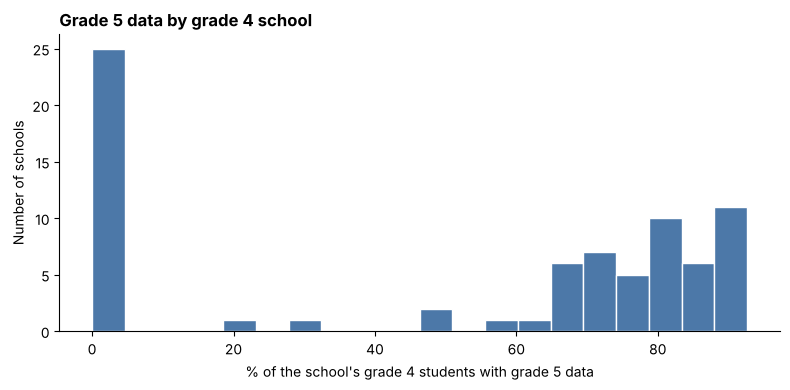

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(by_school["share_g5"] * 100, bins=20, color=BLUE, edgecolor="white")
ax.set_xlabel("% of the school's grade 4 students with grade 5 data")
ax.set_ylabel("Number of schools")
ax.set_title("Grade 5 data by grade 4 school", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../figures/grade5_by_school.png", dpi=200)
plt.show()

In [10]:
# Of the students that DO have grade 5 data: did they stay in the same school?
both = g4[g4["in_g5"] == 1]
same = (both["g4schid"] == both["g5schid"]).mean()
print(f"Students with grade 5 data who are in the same school as in grade 4: {same:.0%}")

Students with grade 5 data who are in the same school as in grade 4: 92%


**What we see:** two things happen at once.

- **22 schools (about 1,070 students) have no grade 5 data at all.** Whole schools were lost, which fits the record-matching explanation.
- **No school has all of its students.** Even in the "good" schools, part of the students are missing. So students were also lost one by one.

Students who do have grade 5 data are almost all (92%) still in their grade 4 school. Students who moved to another school
were probably harder to match.

## 4. Who is missing? (selection)

Even if the cause is technical, the students who **are** in the grade 5 data may be different from the others.
We compare students **with** and **without** grade 5 data (all have grade 4 data).

In [11]:
g4["Grade 5 data"] = g4["in_g5"].map({1: "yes", 0: "no"})

def share_table(var):
    t = pd.crosstab(g4[var], g4["Grade 5 data"], normalize="columns") * 100
    return t.round(1)

for var in ["race3", "freelunch", "urban", "gender"]:
    display(share_table(var))

Grade 5 data,no,yes
race3,,
Black,42.2,19.2
Other,0.4,0.6
White,57.4,80.2


Grade 5 data,no,yes
freelunch,,
FREE LUNCH,58.5,34.6
NON-FREE LUNCH,41.5,65.4


Grade 5 data,no,yes
urban,,
INNER CITY,27.8,8.1
RURAL,41.5,57.1
SUBURBAN,23.7,26.8
URBAN,7.0,7.9


Grade 5 data,no,yes
gender,,
FEMALE,47.5,50.0
MALE,52.5,50.0


In [12]:
score_cols = ["g3tmathss", "g4tmathss", "g3treadss", "g4treadss"]
g4.groupby("Grade 5 data")[score_cols].mean().round(1)

,g3tmathss,g4tmathss,g3treadss,g4treadss
Grade 5 data,,,,
no,612.1,700.1,610.1,610.2
yes,626.5,711.6,623.2,623.2


### Logistic regression

We model the chance that a student has grade 5 data, using background variables and the grade 4 math score:

$$
\Pr(\text{G5}_i = 1) = \frac{1}{1 + e^{-(b_0 + b_1 \,\text{race}_i + b_2 \,\text{lunch}_i + b_3 \,\text{urban}_i + b_4 \,\text{gender}_i + b_5 \,\text{math4}_i + b_6 \,\text{small}_i)}}
$$

`math4_z` is the grade 4 math score in standard units (mean 0, SD 1), so its coefficient is "per 1 SD".
We also include `small` already here, but discuss it in step 5.

In [13]:
m = g4.dropna(subset=["race3", "freelunch", "urban", "gender", "g4tmathss", "first_classtype"]).copy()
m["gender"] = m["gender"].astype(str)
m["math4_z"] = (m["g4tmathss"] - m["g4tmathss"].mean()) / m["g4tmathss"].std()
print("Students in the model:", len(m))

logit = smf.logit(
    "in_g5 ~ C(race3, Treatment('White')) + C(freelunch) + C(urban) + C(gender) + math4_z + small",
    data=m).fit(disp=0)

odds = pd.DataFrame({
    "odds ratio": np.exp(logit.params),
    "CI low": np.exp(logit.conf_int()[0]),
    "CI high": np.exp(logit.conf_int()[1]),
    "p-value": logit.pvalues,
}).round(3)
odds

Students in the model: 4308


,odds ratio,CI low,CI high,p-value
Intercept,1.748,1.297,2.357,0.000
"C(race3, Treatment('White'))[T.Black]",0.944,0.769,1.157,0.577
"C(race3, Treatment('White'))[T.Other]",0.957,0.400,2.286,0.920
C(freelunch)[T.NON-FREE LUNCH],1.332,1.158,1.532,0.000
C(urban)[T.RURAL],0.675,0.508,0.896,0.007
C(urban)[T.SUBURBAN],1.029,0.778,1.360,0.843
C(urban)[T.URBAN],0.692,0.493,0.972,0.034
C(gender)[T.MALE],0.893,0.788,1.011,0.073
math4_z,1.247,1.168,1.331,0.000
small,0.983,0.855,1.129,0.804


**How to read it:** an odds ratio above 1 means *more likely* to have grade 5 data, below 1 means *less likely*.

**What we see:**

- In the simple tables, the difference is large: among students with grade 5 data, 80% are White (vs. 57% without),
  35% get free lunch (vs. 59%), and only 8% are from inner-city schools (vs. 28%). They also scored about 11–14 points higher in grades 3–4.
- In the regression, which looks at all variables together, the clearest predictors are **free lunch**
  (non-free lunch: about 1.3 times the odds) and the **grade 4 math score** (about 1.25 times the odds per 1 SD).
  Race is no longer significant once lunch, location and scores are in the model.
- **Class type (`small`) has no effect** (odds ratio 0.98, p = 0.80).

So the grade 5 sample is **not representative**: it is richer, whiter and higher-scoring than the full STAR sample.
Grade 5 **averages** should not be compared directly with other grades.

## 5. Is missingness related to class type?

This is the most important question for us. Our comparison is **small vs. regular** classes.
If both groups lose the **same kinds** of students in grade 5, the comparison is still fair.

First, the share with grade 5 data in each class type, with a $\chi^2$ test of independence.

In [14]:
tab = pd.crosstab(g4["first_classtype"], g4["Grade 5 data"])
tab["% with grade 5"] = (tab["yes"] / tab.sum(axis=1) * 100).round(1)
display(tab)

chi2, p, dof, _ = stats.chi2_contingency(tab[["no", "yes"]])
print(f"Chi-square = {chi2:.2f}, df = {dof}, p = {p:.3f}")

Grade 5 data,no,yes,% with grade 5
first_classtype,,,
REGULAR + AIDE CLASS,1393,933,40.1
REGULAR CLASS,1392,951,40.6
SMALL CLASS,961,709,42.5


Chi-square = 2.36, df = 2, p = 0.307


In [15]:
# Same question, but controlling for school: within the same grade 4 school,
# are small-class students more or less likely to have grade 5 data?
d = g4.dropna(subset=["g4schid"]).copy()
d["school4"] = d["g4schid"].astype(int).astype(str)
lpm = smf.ols("in_g5 ~ small + C(school4)", data=d).fit(
    cov_type="cluster", cov_kwds={"groups": d["school4"]})
print(f"Within school, difference small minus regular in the chance of grade 5 data: "
      f"{lpm.params['small']*100:+.1f} percentage points "
      f"(95% CI {lpm.conf_int().loc['small', 0]*100:+.1f} to {lpm.conf_int().loc['small', 1]*100:+.1f}, "
      f"p = {lpm.pvalues['small']:.3f})")

Within school, difference small minus regular in the chance of grade 5 data: -1.1 percentage points (95% CI -3.1 to +1.0, p = 0.300)


In [16]:
# Do small and regular classes lose the SAME kind of students?
# Grade 4 math score, by class type and grade 5 status.
(g4.assign(group=np.where(g4["small"] == 1, "small", "regular / aide"))
   .pivot_table(index="group", columns="Grade 5 data", values="g4tmathss", aggfunc="mean")
   .round(1))

Grade 5 data,no,yes
group,,
regular / aide,698.3,710.6
small,704.9,714.4


**What we see:** about 40–43% of students in every class type have grade 5 data, and the $\chi^2$ test is not significant (p ≈ 0.31).
Within the same school, the difference is about 1 percentage point and not significant either.
In both groups, the students who are missing had **lower** grade 4 scores than those who stayed, by a similar amount.

So the missing grade 5 data is related to **who the students are and where they study**, but **not to the treatment**.

## 6. Does it change the results?

We estimate the **small-class effect on the grade 5 math score** in three ways, and compare with grades 4 and 6.

The model (ordinary least squares, with school fixed effects because randomization was within schools):

$$
\text{score}_i = a_{s(i)} + b \cdot \text{small}_i + e_i
$$

where $a_{s(i)}$ is a separate intercept for student $i$'s first K–3 school and $b$ is the small-class effect
(in test-score points). Standard errors are clustered by school.

The three versions for grade 5:

1. **All available** – every student with a grade 5 score.
2. **Complete cases** – only students with scores in grades 4, 5 **and** 6.
3. **Weighted (IPW)** – every student with a grade 5 score, weighted by $w_i = 1 / \hat{p}_i$,
   where $\hat{p}_i$ is the predicted chance of having grade 5 data from the logistic regression in step 4.
   Students who "look like" the missing ones get more weight, so the sample looks more like the full grade 4 group.

In [17]:
def small_effect(data, outcome, weights=None):
    d = data.dropna(subset=[outcome, "first_school"]).copy()
    d["first_school"] = d["first_school"].astype(str)
    if weights is None:
        fit = smf.ols(f"{outcome} ~ small + C(first_school)", data=d)
    else:
        fit = smf.wls(f"{outcome} ~ small + C(first_school)", data=d, weights=d[weights])
    r = fit.fit(cov_type="cluster", cov_kwds={"groups": d["first_school"]})
    ci = r.conf_int().loc["small"]
    return pd.Series({"students": len(d), "effect": r.params["small"],
                      "CI low": ci[0], "CI high": ci[1], "p-value": r.pvalues["small"]})

# predicted probability of grade 5 data -> weights (only for students in the logit model)
m["p_hat"] = logit.predict(m)
m["ipw"] = 1 / m["p_hat"]
print("Weights: min {:.1f}, median {:.1f}, max {:.1f}".format(*m["ipw"].quantile([0, .5, 1])))

complete = df[df["g4tmathss"].notna() & df["g5tmathss"].notna() & df["g6tmathss"].notna()]

results = pd.DataFrame({
    "Grade 4 (all)":             small_effect(df, "g4tmathss"),
    "Grade 5 – all available":   small_effect(df, "g5tmathss"),
    "Grade 5 – complete cases":  small_effect(complete, "g5tmathss"),
    "Grade 5 – weighted (IPW)":  small_effect(m[m["in_g5"] == 1], "g5tmathss", weights="ipw"),
    "Grade 6 (all)":             small_effect(df, "g6tmathss"),
}).T
results["students"] = results["students"].astype(int)
results.round(2)

Weights: min 1.2, median 1.7, max 3.6


,students,effect,CI low,CI high,p-value
Grade 4 (all),4331,4.67,1.27,8.07,0.01
Grade 5 – all available,2589,6.38,2.22,10.55,0.00
Grade 5 – complete cases,2271,7.22,3.16,11.27,0.00
Grade 5 – weighted (IPW),2566,6.57,1.96,11.17,0.01
Grade 6 (all),6422,3.70,0.99,6.42,0.01


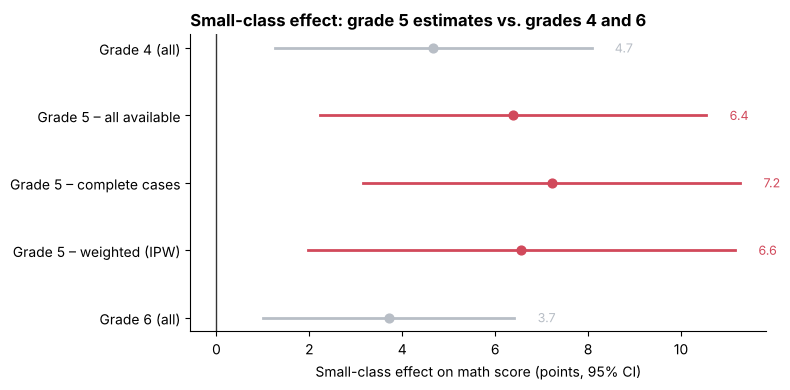

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(results))[::-1]
c = [GREY if "Grade 5" not in i else RED for i in results.index]
for yi, ci, (_, r) in zip(y, c, results.iterrows()):
    ax.plot([r["CI low"], r["CI high"]], [yi, yi], color=ci, lw=2)
    ax.scatter(r["effect"], yi, color=ci, zorder=3, s=40)
    ax.text(r["CI high"] + 0.5, yi, f"{r['effect']:.1f}", va="center", fontsize=9, color=ci)
ax.axvline(0, color="#333", lw=1)
ax.set_yticks(y)
ax.set_yticklabels(results.index)
ax.set_xlabel("Small-class effect on math score (points, 95% CI)")
ax.set_title("Small-class effect: grade 5 estimates vs. grades 4 and 6", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../figures/grade5_effect_estimates.png", dpi=200)
plt.show()

**How to read it:** each dot is the estimated effect of being in a small class in K–3, in math score points.
The line is the 95% confidence interval. If the line crosses 0, the effect is not significant.

**What we see:** the three grade 5 versions give almost the same effect, about **6.4 to 7.2 points**, all significant.
Weighting the sample to look like the full grade 4 group (IPW) barely changes the result (6.4 → 6.6).
The grade 5 effect is a bit larger than in grade 4 (4.7) and grade 6 (3.7), but the confidence intervals overlap a lot,
so we should not read much into that difference.

## 7. Conclusion

1. **The drop is mostly missing records, not dropout.** About two thirds of the students missing in grade 5 come back
   in grade 6 (step 2). 22 schools have no grade 5 data at all, and the other schools lost part of their students (step 3).
   This matches the user guide: grade 5 records were not fully matched with the state files.
2. **The grade 5 sample is not representative.** It has fewer free-lunch, Black and inner-city students
   and higher earlier scores (step 4). Grade 5 **averages** should not be compared directly with other grades.
3. **The missingness is not related to class type** (step 5). Small, regular and regular + aide classes lose
   about the same share of students, and the same kind of students. So the **comparison** between them in grade 5 is still fair.
4. **The effect does not depend on how we handle the gap** (step 6). All three grade 5 estimates are about 6–7 points,
   in the same range as grades 4 and 6.

### Decision for the main analysis

- **Keep grade 5** in the "does the effect last?" analysis, with a note about the smaller, non-representative sample.
- Report the **weighted (IPW)** grade 5 estimate next to the regular one as a robustness check.
- Base the main conclusion on **grades 4, 6 and 8**, where the samples are much larger.
- Later: check the smaller gap in **grade 4 math** (about 4,300 math scores vs. 6,000 reading scores).

## Notes

_Write here what you noticed: surprises, questions, things to check later._